# Latent Diffusion Sampling and Image Editing

Portfolio edition: Behrad Mazaheri. Template/source credit: Original source/template attribution retained.

**Static review only — not rerun.** Outputs below are retained from `P3_completed_reviewed.ipynb`, including failures or missing executions. They do not validate later revisions. Read README and REVIEW before running cells or citing metrics. Source cell references use zero-based indices before this added banner.


# Student Information

**Full name:** ____________behrad mazaheri___________________

**Student number:** __________________[student ID removed]_____________

---


# Homework — The Mechanics of Diffusion-Based Image Editing
### Latent space, the noise schedule, the reverse process, classifier-free guidance, and CLIP conditioning

**Free on a Colab T4. Open weights only — no paid API, no cloud billing.**

Instead of treating the model as a black box, you will **take a latent-diffusion model apart** and rebuild its sampling loop by hand, then use that understanding to edit images.

You touch these deep-learning concepts directly:
| Part | DL concept |
|---|---|
| 1 | Autoencoders / **VAE** latent compression, reconstruction error (PSNR) |
| 2 | **Forward diffusion** $q(x_t\mid x_0)$, noise schedule, signal-to-noise ratio |
| 3 | **Reverse process**: U-Net ε-predictor + sampler (DDIM), hand-written loop |
| 4 | **Classifier-free guidance** — derive and implement the guidance equation |
| 5 | **Conditioning**: CLIP text embeddings, cross-attention, embedding interpolation |
| 6 | **Applications**: instruction editing (InstructPix2Pix) + inpainting |

All implementation tasks and written questions are completed below.
**Estimated time: 3-4 h.** Set `Runtime > Change runtime type > T4 GPU` first.


## Part 0 — Setup


In [1]:
# Pinned for reproducibility. On a torch mismatch: Runtime > Restart session, then re-run.
%pip install -q "diffusers==0.31.0" "transformers==4.44.2" \
    "accelerate==0.34.2" "safetensors>=0.4.2" "huggingface_hub==0.25.2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 436.6/436.6 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 49.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.25.2 which is incompatible.


### Hugging Face login (required)
Colab's shared IPs are rate-limited by the Hub, so **anonymous** downloads fail with `401`. Authenticate with a free token:
1. Create a **Read** token at https://huggingface.co/settings/tokens
2. In Colab, click the 🔑 (**Secrets**) icon in the left sidebar → **Add new secret** → name it `HF_TOKEN`, paste the token, and enable **Notebook access**.
3. Run the next cell. (Never paste the token directly into code.)


In [2]:
from huggingface_hub import login
try:
    from google.colab import userdata
    login(userdata.get('HF_TOKEN'))          # reads the Colab secret named HF_TOKEN
except Exception as e:
    print('Colab secret not found; falling back to manual login.')
    login()                                   # paste your Read token when prompted
print('Hugging Face login OK')

Colab secret not found; falling back to manual login.


Hugging Face login OK


In [3]:
import torch, math, time
import matplotlib.pyplot as plt
print('CUDA:', torch.cuda.is_available())
assert torch.cuda.is_available(), 'Enable GPU: Runtime > Change runtime type > T4 GPU'
print('GPU:', torch.cuda.get_device_name(0))
DEVICE, DTYPE = 'cuda', torch.float16

CUDA: True
GPU: Tesla T4


In [4]:
import io, requests, gc
from PIL import Image
from torchvision import transforms as T

to_tensor, to_pil = T.ToTensor(), T.ToPILImage()

def load_image(url_or_path, size=(512, 512)):
    if str(url_or_path).startswith('http'):
        response = requests.get(url_or_path, timeout=30)
        response.raise_for_status()
        img = Image.open(io.BytesIO(response.content))
    else:
        img = Image.open(url_or_path)
    return img.convert('RGB').resize(size)

def show(*imgs, titles=None):
    n = len(imgs)
    fig, ax = plt.subplots(1, n, figsize=(4.5 * n, 4.5))
    ax = [ax] if n == 1 else ax
    for a, im in zip(ax, imgs):
        a.imshow(im)
        a.axis('off')
    if titles:
        for a, title in zip(ax, titles):
            a.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()

def free_memory(*objs):
    # Moving complete pipelines to CPU releases their CUDA parameters.
    for obj in objs:
        if hasattr(obj, 'to'):
            try:
                obj.to('cpu')
            except Exception:
                pass
    del objs
    gc.collect()
    torch.cuda.empty_cache()


### Load a base latent-diffusion model and expose its components
Stable Diffusion is a **latent** diffusion model with four pieces: a **VAE** (`vae`), a **U-Net** noise predictor (`unet`), a **CLIP text encoder** (`text_encoder` + `tokenizer`), and a **scheduler** (the sampler). We grab them individually so we can drive the process ourselves.


In [5]:
from diffusers import StableDiffusionPipeline, DDIMScheduler

# NOTE: the official 'stabilityai/stable-diffusion-2-1-base' repo was deprecated/removed
# from the Hub (returns 404). We use a community mirror with identical weights.
pipe = StableDiffusionPipeline.from_pretrained(
    'Manojb/stable-diffusion-2-1-base', torch_dtype=DTYPE).to(DEVICE)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

vae, unet = pipe.vae, pipe.unet
text_encoder, tokenizer, scheduler = pipe.text_encoder, pipe.tokenizer, pipe.scheduler
print('unet in_channels:', unet.config.in_channels,
      '| latent scale factor:', vae.config.scaling_factor,
      '| train timesteps:', scheduler.config.num_train_timesteps)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_token.py:90: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/543 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

...

model.safetensors:   0%|          | 0.00/1.36G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


unet in_channels: 4 | latent scale factor: 0.18215 | train timesteps: 1000


## Part 1 — The latent space (the VAE)
Diffusion here does **not** run on pixels. The VAE encoder maps a `3x512x512` image to a `4x64x64` **latent**, and the decoder maps it back. Everything in Parts 2-6 happens in that small latent space.


In [6]:
@torch.no_grad()
def encode(img):
    x = to_tensor(load_image(img) if isinstance(img, str) else img)
    x = (x * 2 - 1).unsqueeze(0).to(DEVICE, DTYPE)      # scale to [-1, 1]
    lat = vae.encode(x).latent_dist.sample()
    return lat * vae.config.scaling_factor

@torch.no_grad()
def decode(lat):
    x = vae.decode(lat / vae.config.scaling_factor).sample
    x = (x / 2 + 0.5).clamp(0, 1)[0].float().cpu()
    return to_pil(x)

### Task 1.1 — Measure the compression
> **Completed task:** Encode any image and print (a) the pixel tensor shape `3x512x512`, (b) the latent shape, and (c) the **compression ratio** = pixel elements / latent elements.


In [7]:
img = load_image('https://huggingface.co/datasets/hf-internal-testing/diffusers-images/'
                 'resolve/main/in_paint/overture-creations-5sI6fQgYIuo.png')
z = encode(img)

pixel_tensor = to_tensor(img)
pixel_elements = pixel_tensor.numel()
latent_elements = z[0].numel()  # exclude the batch dimension
compression_ratio = pixel_elements / latent_elements

print('Pixel tensor shape :', tuple(pixel_tensor.shape))
print('Latent tensor shape:', tuple(z.shape))
print(f'Pixel elements      : {pixel_elements:,}')
print(f'Latent elements     : {latent_elements:,}')
print(f'Compression ratio   : {compression_ratio:.2f}x')


Pixel tensor shape : (3, 512, 512)
Latent tensor shape: (1, 4, 64, 64)
Pixel elements      : 786,432
Latent elements     : 16,384
Compression ratio   : 48.00x


### Task 1.2 — Reconstruction error
The VAE is *lossy*. Round-trip the image (encode then decode), show both, and compute **PSNR**.
> **Completed task:** Complete the PSNR function and report the value.


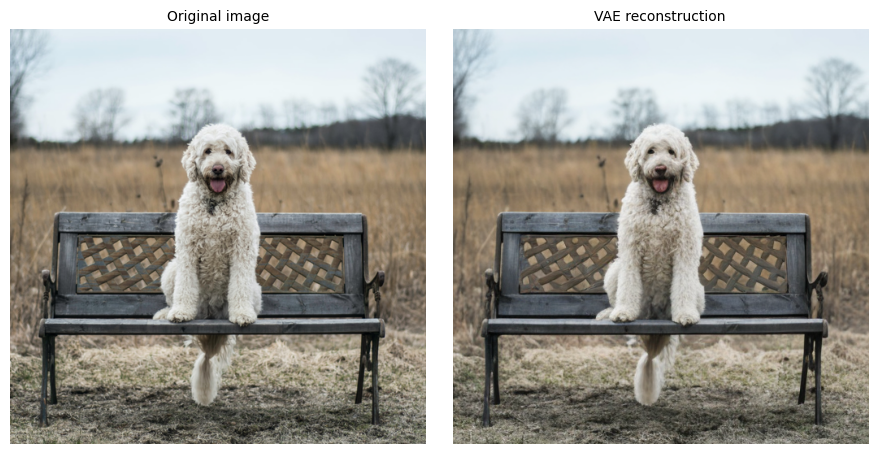

VAE reconstruction PSNR: 25.67 dB


In [8]:
import numpy as np

def psnr(a, b):
    a = np.asarray(a, np.float32) / 255.0
    b = np.asarray(b, np.float32) / 255.0
    mse = np.mean((a - b) ** 2)
    return float('inf') if mse == 0 else 10.0 * math.log10(1.0 / mse)

recon = decode(z)
vae_psnr = psnr(img, recon)
show(img, recon, titles=['Original image', 'VAE reconstruction'])
print(f'VAE reconstruction PSNR: {vae_psnr:.2f} dB')


> **Q1.** A pixel-space diffusion model would denoise a `3x512x512` tensor at every step; this model denoises `4x64x64`. Using your compression ratio, explain *quantitatively* why latent diffusion is so much cheaper, and state what is sacrificed (use your PSNR number).


*Answer to Q1 (based on the saved output):*

The saved run reports

$$
3\times512\times512=786{,}432
$$

pixel values and

$$
4\times64\times64=16{,}384
$$

latent values. Therefore,

$$
\text{compression ratio}=\frac{786{,}432}{16{,}384}=48.
$$

Thus the U-Net denoises a representation with **48 times fewer scalar elements**. Spatially, it works on only (64\times64=4{,}096) positions instead of (512\times512=262{,}144), a **64-fold reduction in spatial positions**. The wall-clock speedup is not exactly (48\times), because channel widths, convolutions, attention, and VAE encoding/decoding also cost computation; nevertheless, the reduction in activation size greatly lowers compute and memory use.

The cost is lossy VAE reconstruction. In this run, the round trip produced

$$
\boxed{\text{PSNR}=25.67\ \text{dB}}.
$$

The reconstruction preserves the dog, bench, and global composition well, but the saved comparison shows mild smoothing and loss of fine texture. A perfect reconstruction would have zero MSE and infinite PSNR, so the finite (25.67\) dB directly measures the information sacrificed for latent-space efficiency.

## Part 2 — The forward diffusion process
The forward process gradually destroys a latent with Gaussian noise:

$$q(x_t\mid x_0)=\mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\;(1-\bar\alpha_t)\mathbf{I}\big)\quad\Longleftrightarrow\quad x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$$

where $\bar\alpha_t$ is the cumulative product of the noise schedule and $\epsilon\sim\mathcal N(0,\mathbf I)$.


### Task 2.1 — Watch a latent dissolve into noise
> **Completed task:** For timesteps `t in [0, 100, 300, 500, 800, 999]`, use `scheduler.add_noise` to noise the latent `z`, **decode each** noisy latent, and display the sequence. (This is the closed-form `x_t` above — no loop needed.)


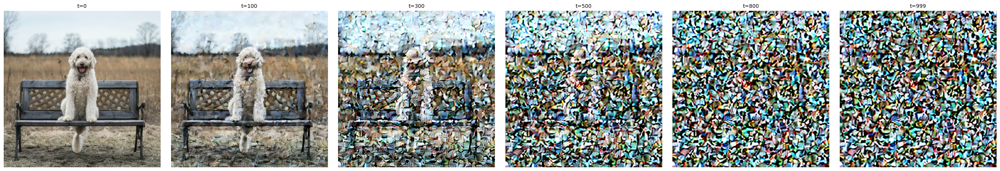

In [9]:
ts = [0, 100, 300, 500, 800, 999]
eps = torch.randn_like(z)
noised = []

for t in ts:
    t_tensor = torch.tensor([t], device=z.device, dtype=torch.long)
    x_t = scheduler.add_noise(z, eps, t_tensor)
    noised.append(decode(x_t))

show(*noised, titles=[f't={t}' for t in ts])


### Task 2.2 — Plot the schedule and the SNR
`scheduler.alphas_cumprod` is the $\bar\alpha_t$ curve (length 1000). The per-step **signal-to-noise ratio** is $\text{SNR}(t)=\bar\alpha_t/(1-\bar\alpha_t)$.
> **Completed task:** Plot $\bar\alpha_t$ vs $t$, and $\log \text{SNR}(t)$ vs $t$, as two curves.


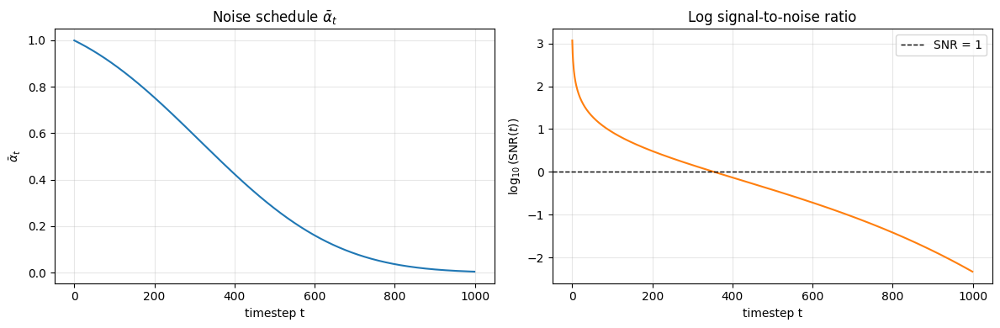

In [10]:
ac = scheduler.alphas_cumprod.float().cpu().numpy()
t_axis = np.arange(len(ac))
snr = ac / np.clip(1.0 - ac, 1e-12, None)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t_axis, ac, color='tab:blue')
axes[0].set(
    title=r'Noise schedule $\bar{\alpha}_t$',
    xlabel='timestep t',
    ylabel=r'$\bar{\alpha}_t$',
)
axes[0].grid(alpha=0.3)

axes[1].plot(
    t_axis,
    np.log10(np.clip(snr, 1e-12, None)),
    color='tab:orange',
)
axes[1].axhline(
    0.0,
    color='black',
    linestyle='--',
    linewidth=1,
    label='SNR = 1',
)
axes[1].set(
    title='Log signal-to-noise ratio',
    xlabel='timestep t',
    ylabel=r'$\log_{10}(\mathrm{SNR}(t))$',
)
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


> **Q2.** (a) From the equation, write the mean and variance of $x_t$ in terms of $\bar\alpha_t$. (b) Because the schedule keeps $\text{mean}^2+\text{var}$ roughly constant, this is called a *variance-preserving* process — verify this qualitatively from your plot. (c) At which end of the $t$ axis is the U-Net's denoising job hardest, and why?


*Answer to Q2 (based on the saved plots):*

**(a)** Conditioned on (x_0),

$$
q(x_t\mid x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_t}x_0,\,(1-\bar\alpha_t)I\right),
$$

so

$$
\mathbb E[x_t\mid x_0]=\sqrt{\bar\alpha_t}\,x_0,
\qquad
\operatorname{Cov}(x_t\mid x_0)=(1-\bar\alpha_t)I.
$$

Each scalar component therefore has mean (sqrt{\bar\alpha_t}x_0) and variance (1-\bar\alpha_t).

**(b)** In the saved schedule plot, (\bar\alpha_t) falls smoothly from about (1) at the left end to almost (0) near (t=999). Consequently, the squared signal coefficient (\bar\alpha_t) is replaced by noise variance (1-\bar\alpha_t). If the clean latent is approximately unit variance,

$$
\operatorname{Var}(x_t)
=\bar\alpha_t\operatorname{Var}(x_0)+(1-\bar\alpha_t)
\approx \bar\alpha_t+(1-\bar\alpha_t)=1.
$$

This agrees qualitatively with a variance-preserving process. The saved log-SNR curve decreases continuously and crosses (log\mathrm{SNR}=0) (that is, (mathrm{SNR}=1)) at roughly the middle-left of the timeline, where signal and noise powers are equal. The decoded sequence confirms the same behavior: the image is clear at (t=0), visibly corrupted by (t=300), dominated by noise around (t=500), and essentially noise at (t=800) and (999).

**(c)** Reconstructing image content is hardest at the **high-(t) end**, because (\bar\alpha_t) and the SNR are smallest there. The current latent contains almost no directly visible evidence about (x_0), so the U-Net must rely strongly on its learned image prior and text condition. Predicting the added noise itself is not necessarily numerically hardest at high (t), because noise dominates the input; the difficult generative task is recovering the correct clean semantic content from that low-SNR state.

## Part 3 — The reverse process, by hand
Sampling = start from pure noise $x_T$ and iteratively denoise. At each step the **U-Net** predicts the noise $\epsilon_\theta(x_t,t,c)$ and the **sampler** (`scheduler.step`) uses it to estimate $x_{t-1}$. You will write this loop yourself instead of calling `pipe(...)`.


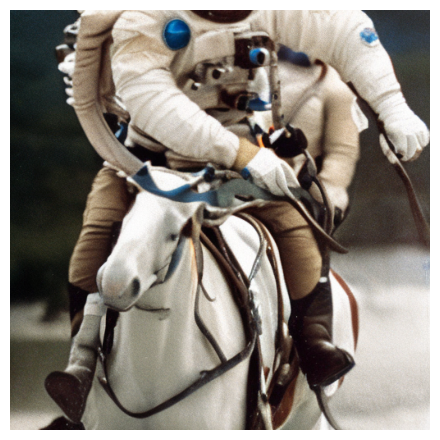

In [11]:
@torch.no_grad()
def embed(prompt):
    tok = tokenizer(prompt, padding='max_length', max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors='pt').input_ids.to(DEVICE)
    return text_encoder(tok)[0]                          # [1, 77, 1024]

@torch.no_grad()
def sample(prompt, steps=25, guidance=7.5, seed=0):
    cond, uncond = embed(prompt), embed('')
    emb = torch.cat([uncond, cond])                      # batch the two passes
    gen = torch.Generator(DEVICE).manual_seed(seed)
    x = torch.randn((1, unet.config.in_channels, 64, 64),
                    generator=gen, device=DEVICE, dtype=DTYPE)
    scheduler.set_timesteps(steps)
    x = x * scheduler.init_noise_sigma
    for t in scheduler.timesteps:
        inp = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_cond = unet(inp, t, encoder_hidden_states=emb).sample.chunk(2)
        # --- classifier-free guidance (you edit this line in Part 4) ---
        eps = eps_uncond + guidance * (eps_cond - eps_uncond)
        x = scheduler.step(eps, t, x).prev_sample
    return decode(x)

show(sample('a photograph of an astronaut riding a horse', steps=25, seed=0))

### Task 3.1 — Steps vs. quality (sampler as an ODE solver)
DDIM is a deterministic solver of the probability-flow ODE; fewer steps = coarser integration.
> **Completed task:** Generate the **same prompt and seed** at `steps in [4, 10, 25, 50]`, timing each, and display the four results with their wall-clock times in the titles.


 4 steps: 0.68 s
10 steps: 1.43 s
25 steps: 3.19 s
50 steps: 6.21 s


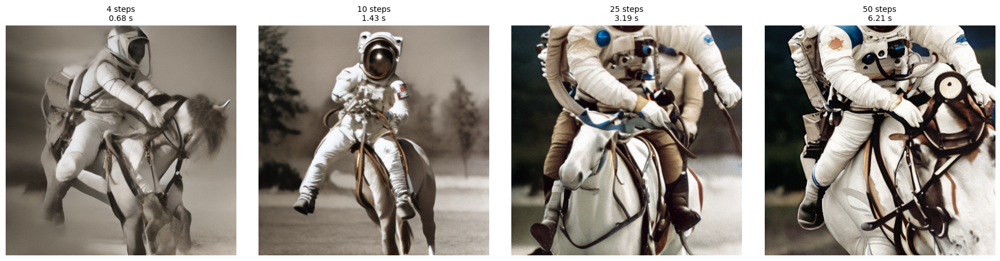

In [12]:
prompt = 'a photograph of an astronaut riding a horse'
step_counts = [4, 10, 25, 50]
step_outputs, step_times = [], []

for num_steps in step_counts:
    torch.cuda.synchronize()
    start = time.perf_counter()
    result = sample(prompt, steps=num_steps, guidance=7.5, seed=0)
    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    step_outputs.append(result)
    step_times.append(elapsed)
    print(f'{num_steps:>2} steps: {elapsed:.2f} s')

show(
    *step_outputs,
    titles=[f'{s} steps\n{dt:.2f} s' for s, dt in zip(step_counts, step_times)],
)


> **Q3.** Explain why DDIM produces a coherent image in ~10-25 steps while the original DDPM sampler needs hundreds. Frame your answer in terms of *deterministic vs. stochastic* sampling and step size of the ODE solver.


*Answer to Q3 (based on the saved timing and images):*

DDPM ancestral sampling follows a **stochastic** reverse Markov chain. Each transition performs a relatively small denoising update and normally injects fresh random noise, so accurately following the original discretized chain requires hundreds of small steps.

DDIM can set (eta=0), removing the newly injected stochastic noise. For a fixed initial noise, its trajectory is then **deterministic** and can be viewed as integrating a smooth probability-flow trajectory while skipping many of the 1000 training timesteps. This permits much larger solver steps than ancestral DDPM. Too few steps, however, make the numerical trajectory coarse and increase discretization error.

The saved experiment shows the expected quality-speed tradeoff:

| DDIM steps | Saved time | Observed result |
|---:|---:|---|
| 4 | 0.68 s | Prompt is recognizable, but the scene is soft and the astronaut/horse geometry is poorly resolved. |
| 10 | 1.43 s | A coherent astronaut-on-horse composition appears, with better global structure but limited detail. |
| 25 | 3.19 s | Details, contrast, and prompt alignment are substantially clearer. |
| 50 | 6.21 s | A refined coherent image is obtained, but runtime is almost twice that of 25 steps and the improvement is smaller than the cost increase. |

Thus this run demonstrates why roughly 10–25 DDIM steps can already be coherent: deterministic sampling follows a smoother path with large steps. Four steps are too coarse, while moving from 25 to 50 gives diminishing visual returns.

## Part 4 — Classifier-free guidance (CFG)
The guidance line in `sample()` implements

$$\hat\epsilon=\epsilon_\theta(x_t,\varnothing)+s\,\big(\epsilon_\theta(x_t,c)-\epsilon_\theta(x_t,\varnothing)\big)$$

where $s$ is `guidance` and $\varnothing$ is the empty prompt. The model is trained with random prompt-dropout so it can produce both $\epsilon_\theta(x_t,c)$ and $\epsilon_\theta(x_t,\varnothing)$.


### Task 4.1 — Sweep the guidance scale
> **Completed task:** Fix prompt + seed and generate at `guidance in [1, 3, 7.5, 15, 25]`. Show all five. Note the washed-out image at `s=1` and the over-saturated, high-contrast artefacts at `s=25`.


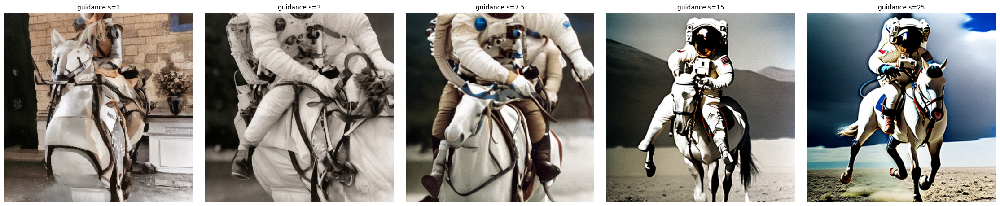

In [13]:
guidance_scales = [1.0, 3.0, 7.5, 15.0, 25.0]
guidance_outputs = [
    sample(prompt, steps=25, guidance=g, seed=0)
    for g in guidance_scales
]
show(
    *guidance_outputs,
    titles=[f'guidance s={g:g}' for g in guidance_scales],
)


> **Q4.** (a) What image does `s=1` correspond to (look at the equation)? (b) Rewrite $\hat\epsilon$ as an extrapolation between the unconditional and conditional predictions, and use that to explain the over-saturation at large `s`. (c) InstructPix2Pix (Part 6) uses a **triple** guidance with separate scales $s_T$ (text) and $s_I$ (image):
$$\hat\epsilon=\epsilon(x,\varnothing,\varnothing)+s_I\big(\epsilon(x,c_I,\varnothing)-\epsilon(x,\varnothing,\varnothing)\big)+s_T\big(\epsilon(x,c_I,c_T)-\epsilon(x,c_I,\varnothing)\big).$$
Map $s_T$ and $s_I$ onto the intuitive knobs "follow the instruction more" and "stay closer to the input image."


*Answer to Q4 (based on the saved CFG sweep and editing output):*

**(a)** At (s=1),

$$
\hat\epsilon=\epsilon_u+(\epsilon_c-\epsilon_u)=\epsilon_c,
$$

so the sampler uses the ordinary conditional prediction with no extra guidance extrapolation. A purely unconditional prediction would be (s=0). In the saved sweep, (s=1) still produces an astronaut/horse-like scene, but it is weakly conditioned, low-detail, and washed out compared with the (s=7.5) result.

**(b)** The equation can be rewritten as

$$
\hat\epsilon=(1-s)\epsilon_u+s\epsilon_c.
$$

For (0\le s\le1), this is an interpolation. For (s>1), the coefficient of (\epsilon_u) becomes negative, so the model extrapolates beyond (\epsilon_c), away from the unconditional prediction. Moderate extrapolation strengthens prompt-related features. The saved outputs show this progression clearly: (s=3) is still muted, (s=7.5) gives the most balanced detailed result, (s=15) becomes harsh and stylized with clipped bright regions, and (s=25) has severe saturation, edge halos, extreme contrast, and distorted geometry. Large guidance magnifies both prompt-correlated directions and prediction errors at every reverse step.

**(c)** For InstructPix2Pix,

$$
\hat\epsilon=\epsilon_{\varnothing,\varnothing}
+s_I(\epsilon_{I,\varnothing}-\epsilon_{\varnothing,\varnothing})
+s_T(\epsilon_{I,T}-\epsilon_{I,\varnothing}).
$$

- (s_T) is the **follow the instruction more strongly** knob.
- (s_I) is the **stay closer to the input image** knob.

The saved chain used (s_T=7.5) and (s_I=1.5). After the first instruction, the David statue disappears and the output is dominated by the sunset; the later watercolor and snow edits then operate on that already-drifted image. This is direct evidence of weak input preservation and cumulative error in iterative editing. Increasing (s_I), reducing (s_T), or applying the edits from the original image rather than repeatedly feeding outputs back would better preserve the statue.

## Part 5 — Conditioning: CLIP embeddings and cross-attention
The text prompt enters the U-Net only through **cross-attention** to the CLIP text embedding (shape `77 x 1024`: 77 token slots, 1024-dim each). Here we probe that embedding space.


### Task 5.1 — Prompt similarity
> **Completed task:** Embed three prompts (two similar, one different), mean-pool over the 77 tokens to get one vector each, and print the pairwise **cosine similarities**.


In [14]:
import torch.nn.functional as Fn
from itertools import combinations

prompts = ['a photo of a cat', 'a photo of a kitten', 'a photo of a truck']
pooled = {
    prompt_text: embed(prompt_text).mean(dim=1).float()
    for prompt_text in prompts
}

for first, second in combinations(prompts, 2):
    similarity = Fn.cosine_similarity(
        pooled[first],
        pooled[second],
        dim=-1,
    ).item()
    print(f'{first!r}  vs  {second!r}: {similarity:.4f}')


'a photo of a cat'  vs  'a photo of a kitten': 0.9943
'a photo of a cat'  vs  'a photo of a truck': 0.9859
'a photo of a kitten'  vs  'a photo of a truck': 0.9810


### Task 5.2 — Interpolating in embedding space
Because conditioning is a continuous vector, we can walk *between* two prompts.
> **Completed task:** Build a modified sampler that accepts a precomputed conditional embedding, then linearly interpolate `emb = (1-a)*embA + a*embB` for `a in [0, 0.25, 0.5, 0.75, 1.0]` (same seed) and show the semantic morph.


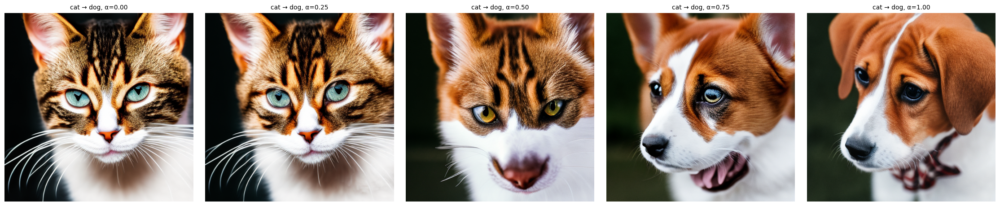

In [15]:
@torch.no_grad()
def sample_emb(cond, steps=25, guidance=7.5, seed=0):
    emb = torch.cat([embed(''), cond])
    gen = torch.Generator(DEVICE).manual_seed(seed)
    x = torch.randn(
        (1, unet.config.in_channels, 64, 64),
        generator=gen,
        device=DEVICE,
        dtype=DTYPE,
    )
    scheduler.set_timesteps(steps)
    x = x * scheduler.init_noise_sigma
    for t in scheduler.timesteps:
        inp = scheduler.scale_model_input(torch.cat([x] * 2), t)
        eps_uncond, eps_cond = unet(
            inp,
            t,
            encoder_hidden_states=emb,
        ).sample.chunk(2)
        guided_eps = eps_uncond + guidance * (eps_cond - eps_uncond)
        x = scheduler.step(guided_eps, t, x).prev_sample
    return decode(x)

emb_a = embed('a photo of a cat')
emb_b = embed('a photo of a dog')
interpolation_weights = [0.0, 0.25, 0.5, 0.75, 1.0]
interpolation_outputs = []

for alpha in interpolation_weights:
    interpolated = (1.0 - alpha) * emb_a + alpha * emb_b
    interpolation_outputs.append(
        sample_emb(interpolated, steps=25, seed=0)
    )

show(
    *interpolation_outputs,
    titles=[f'cat → dog, α={alpha:.2f}' for alpha in interpolation_weights],
)


> **Q5.** Cross-attention lets *each spatial location* of the latent attend to the 77 text tokens. Using your Task 5.2 morph, argue whether the transition is *semantic* (the concept changes) or merely a *pixel blend* of two images, and say what that implies about where meaning lives in this model.


*Answer to Q5 (based on the saved similarity scores and morph):*

The similarity probe has the correct ordering: cat–kitten is highest at **0.9943**, cat–truck is **0.9859**, and kitten–truck is **0.9810**. The absolute scores are all unusually high because the notebook uses a naive mean over all 77 token positions; common template tokens, end/padding positions, and shared CLIP structure dominate the pooled vector. Even so, the ranking still places the semantically closest pair first.

The interpolation output is clearly a **semantic morph**, not a pixel cross-fade. With the seed fixed, (alpha=0) produces a cat; (alpha=0.25) remains cat-like; (alpha=0.50) produces a coherent cat/dog hybrid; (alpha=0.75) is mostly dog-like; and (alpha=1) produces a dog. Facial structure, ears, muzzle, fur pattern, and pose are regenerated consistently at each point rather than appearing as two transparent endpoint images overlaid on one another.

Every value of (alpha) reruns the full nonlinear denoising process from the same initial latent noise. Only the conditioning sequence

$$
(1-\alpha)e_{\text{cat}}+\alpha e_{\text{dog}}
$$

changes. Cross-attention lets each spatial U-Net feature query these continuously changing token representations throughout sampling. Therefore meaning is encoded in the geometry of the CLIP conditioning space and in how the U-Net reads that space through cross-attention, not in endpoint pixels. The visual path need not be linear even though the embedding interpolation is linear, because the denoising network is nonlinear.

## Part 6 — Applications: instruction editing and inpainting
Now use two specialised models. First free the base model's VRAM.


In [16]:
free_memory(pipe)
del pipe, unet, vae, text_encoder, tokenizer, scheduler
gc.collect()
torch.cuda.empty_cache()
print('freed base model')


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

freed base model


### Task 6.1 — Iterative instruction editing (InstructPix2Pix)
InstructPix2Pix conditions on the **input image latent** (concatenated to the U-Net input) *and* a text instruction — the triple-CFG model from Q4.
> **Completed task:** Apply a chain of **≥3 successive instructions**, feeding each output back in. Show all steps.


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

...

config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

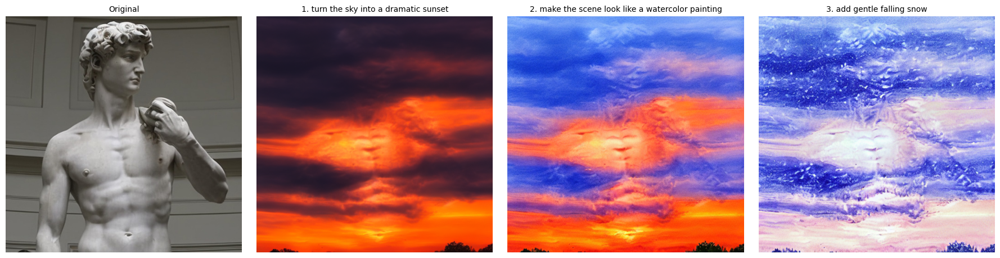

In [17]:
from diffusers import StableDiffusionInstructPix2PixPipeline, EulerAncestralDiscreteScheduler

ip2p = StableDiffusionInstructPix2PixPipeline.from_pretrained(
    'timbrooks/instruct-pix2pix',
    torch_dtype=DTYPE,
    safety_checker=None,
).to(DEVICE)
ip2p.scheduler = EulerAncestralDiscreteScheduler.from_config(ip2p.scheduler.config)
ip2p.set_progress_bar_config(disable=True)

base_img = load_image(
    'https://raw.githubusercontent.com/timothybrooks/instruct-pix2pix/'
    'main/imgs/example.jpg'
)
instructions = [
    'turn the sky into a dramatic sunset',
    'make the scene look like a watercolor painting',
    'add gentle falling snow',
]

edit_images = [base_img]
current = base_img
for index, instruction in enumerate(instructions):
    generator = torch.Generator(DEVICE).manual_seed(100 + index)
    current = ip2p(
        instruction,
        image=current,
        num_inference_steps=20,
        image_guidance_scale=1.5,
        guidance_scale=7.5,
        generator=generator,
    ).images[0]
    edit_images.append(current)

show(
    *edit_images,
    titles=['Original'] + [
        f'{i + 1}. {text}' for i, text in enumerate(instructions)
    ],
)


### Task 6.2 — Inpainting and the U-Net input channels
The inpainting U-Net takes **9 input channels** = 4 (noisy latent) + 1 (mask) + 4 (masked-image latent), versus 4 for the base model. That is how it "sees" the hole and the surroundings.


In [18]:
free_memory(ip2p)
del ip2p
gc.collect()
torch.cuda.empty_cache()

from diffusers import StableDiffusionInpaintPipeline

# Community mirror of the deprecated Stable Diffusion 2 inpainting repo.
inpaint = StableDiffusionInpaintPipeline.from_pretrained(
    'sd2-community/stable-diffusion-2-inpainting',
    torch_dtype=DTYPE,
    safety_checker=None,
).to(DEVICE)
inpaint.set_progress_bar_config(disable=True)
print('inpaint U-Net in_channels:', inpaint.unet.config.in_channels)  # expect 9


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, du

model_index.json:   0%|          | 0.00/544 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.46G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

inpaint U-Net in_channels: 9


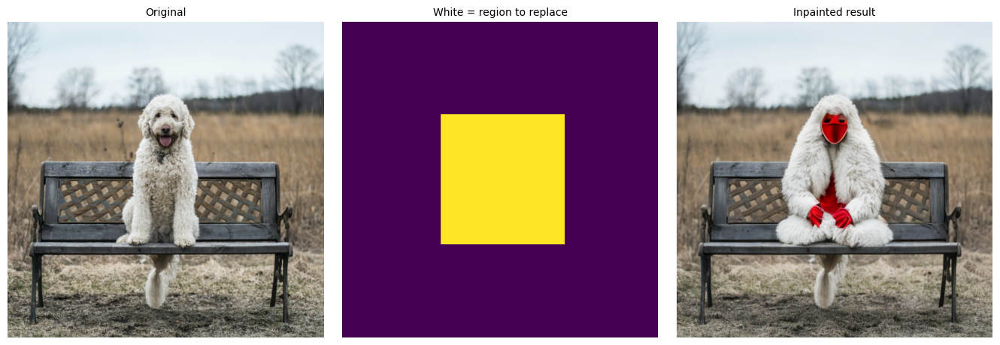

In [19]:
from PIL import ImageDraw

def rect_mask(size, box):
    mask = Image.new('L', size, 0)
    ImageDraw.Draw(mask).rectangle(box, fill=255)
    return mask

my_mask = rect_mask(img.size, (160, 150, 360, 360))
inpaint_prompt = (
    'a natural photograph with a bright red armchair in the masked area'
)
inpaint_result = inpaint(
    prompt=inpaint_prompt,
    image=img,
    mask_image=my_mask,
    num_inference_steps=25,
    guidance_scale=7.5,
    generator=torch.Generator(DEVICE).manual_seed(0),
).images[0]

show(
    img,
    my_mask,
    inpaint_result,
    titles=['Original', 'White = region to replace', 'Inpainted result'],
)


> **Q6.** The base text-to-image U-Net has 4 input channels; the inpainting one has 9. Explain what each extra channel group encodes and why a plain text-to-image model *cannot* do clean local inpainting without them.


*Answer to Q6 (confirmed by the saved model output):*

The notebook prints `inpaint U-Net in_channels: 9`, confirming that its input is composed of:

1. **4 noisy-latent channels:** the current diffusion state (x_t), which the U-Net must denoise.
2. **1 mask channel:** a spatial indicator of the region that may be regenerated versus the region that should remain fixed.
3. **4 masked-image latent channels:** the VAE encoding of the known image with the target region removed. These channels give aligned context such as surrounding geometry, color, texture, and boundaries.

A base text-to-image U-Net receives only the four noisy-latent channels plus a global text condition. It is not explicitly told where the hole is and does not receive a spatially aligned representation of the pixels that must be preserved. It may therefore alter the whole scene and cannot reliably join a new object to the existing texture, lighting, or edges. In the inpainting model, the mask answers **where to edit**, while the masked-image latent answers **what surrounding context to match**.

The saved example also shows that these channels enable locality but do not guarantee semantic success: pixels outside the rectangular mask are largely preserved, while the masked region is changed. The generated content, however, is not a clean red armchair; it becomes an unnatural red, humanoid/dog-like structure. Spatial control and prompt satisfaction are separate problems.

## Part 7 — Failure analysis, tied to a mechanism
> **Q7.** Produce **one** failed generation/edit (show it), then explain the failure using a concept from this notebook — e.g. VAE reconstruction limits (Part 1), too-few sampler steps (Part 3), guidance too high/low (Part 4), or weak cross-attention binding (Part 5). Name the mechanism explicitly.


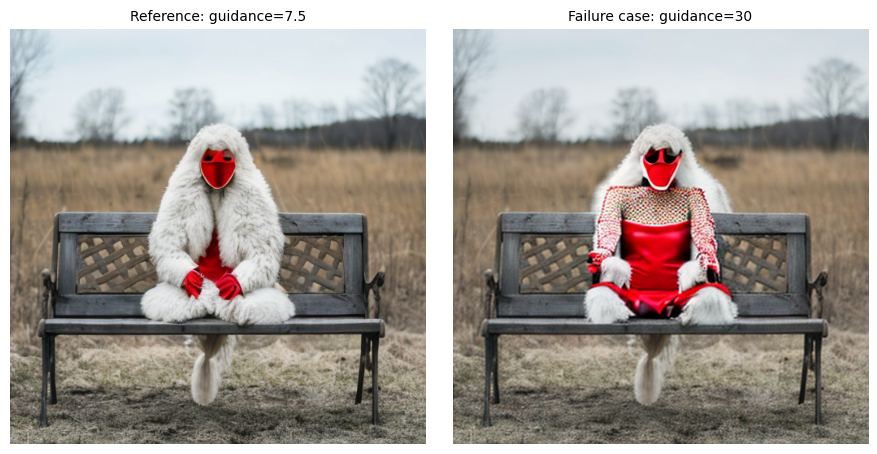

In [20]:
# Deliberately excessive CFG: use the same input, mask, prompt, and seed
# as Task 6.2 so guidance scale is the controlled variable.
failure_guidance = 30.0
failure_result = inpaint(
    prompt=inpaint_prompt,
    image=img,
    mask_image=my_mask,
    num_inference_steps=25,
    guidance_scale=failure_guidance,
    generator=torch.Generator(DEVICE).manual_seed(0),
).images[0]

show(
    inpaint_result,
    failure_result,
    titles=[
        'Reference: guidance=7.5',
        f'Failure case: guidance={failure_guidance:g}',
    ],
)


*Answer to Q7 (based on the saved controlled comparison):*

The failure case changes only classifier-free guidance: the input image, rectangular mask, prompt, seed, and 25 inference steps are identical, while guidance increases from (7.5) to (30).

The saved side-by-side output shows a concrete failure. At (s=7.5), the edit is already imperfect—the requested red armchair is entangled with the dog and becomes a red humanoid/dog-like seated form. At (s=30), the failure becomes much stronger: red regions are overemphasized, the face and torso are distorted, arm/cloth areas acquire harsh checker-like texture, and boundaries have unnaturally high contrast. The output still does not form a clean armchair.

The explicit mechanism is **classifier-free-guidance over-extrapolation**:

$$
\hat\epsilon=(1-s)\epsilon_u+s\epsilon_c.
$$

With (s=30), the estimate is placed far beyond the conditional prediction instead of between the unconditional and conditional predictions. This amplifies not only directions associated with “bright red armchair,” but also model error, incorrect text-to-region binding, and high-frequency artifacts in (\epsilon_c-\epsilon_u). Repeating the exaggerated update over all reverse steps accumulates the distorted anatomy, clipped colors, and patterned texture seen in the result. Because all other variables are fixed, the comparison directly ties the additional degradation to excessive CFG; the remaining semantic failure at (s=7.5) also indicates imperfect cross-attention binding between the object prompt and the masked region.

---
## Submission
1. `Runtime > Run all` so every plot and image renders.
2. `File > Download > Download .ipynb` **with outputs saved**.
3. Submit the `.ipynb` with Q1-Q7 answered. Cleared outputs are auto-zero.
